# La réplica exigente

## TrajDev en el parque B, el mismo modelo, un parque más ruidoso, y lo que el multi-semilla cambia

*Mantenimiento Predictivo para Aerogeneradores Offshore con Restricciones Ambientales. Trabajo de
Fin de Máster. Quinto de los ocho notebooks y tercero de los cuatro de explicabilidad, la pareja del
notebook 1 en el otro parque.*

## Resumen

El notebook 1 presentó a TrajDev como el mejor modelo individual del parque C. La pregunta
siguiente es la de la generalización. ¿Funciona en otro parque, con otros sensores y otro régimen de
ruido, sin retocar nada? Este notebook responde con la réplica en el parque B, la receta de C
aplicada tal cual (misma arquitectura, mismo score `dep_zmax_val`, cero ajuste) sobre los 30
sensores curados de B.

La respuesta tiene dos partes. La primera es que TrajDev-B alcanza CARE-CV 0.6864 ± 0.0083 y supera
al autoencoder de referencia en 4 de las 5 semillas (0.6655 ± 0.0291), perdiendo únicamente
contra la semilla afortunada del AE, igual que en C.

La segunda importa más, y es que **en B el problema cambia de naturaleza**. Las seis anomalías del
parque son fáciles, porque todos los detectores las ven con cientos de horas de antelación y cinco
de las seis disparan por el mismo sensor, pero los nueve periodos normales están tan sucios que
todos los detectores dan falsas alarmas en la mayoría. El parque B no premia ver el fallo, premia
**callar en el ruido**, y ahí es donde tiene que mirar el análisis de explicabilidad. Por eso este
notebook dedica tanta atención a una falsa alarma como a una detección.

## 0. Preparación y verificación

Se cargan los pesos versionados del modelo de campaña, cuyo reentrenamiento reprodujo exactamente
los gates versionados, y los volcados congelados de scores. El gate de reproducción se pasa antes de
dibujar cualquier figura.

In [1]:
# Preparacion del entorno comun a los 4 notebooks XAI
import os, sys, json, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
for p in (str(ROOT), str(ROOT / "scripts")):
    if p not in sys.path:
        sys.path.insert(0, p)
warnings.filterwarnings("ignore")

# ipykernel OutStream no tiene .buffer: evita que el guard utf-8 de los scripts del repo
# (if sys.stdout.encoding != "utf-8": sys.stdout = io.TextIOWrapper(sys.stdout.buffer, ...))
# intente envolverlo al importarlos.
for _s in (sys.stdout, sys.stderr):
    try:
        if getattr(_s, "encoding", None) != "utf-8":
            _s.encoding = "utf-8"
    except Exception:
        pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.xai import (load_ae, load_ae_events, load_meta, load_scores, load_trajdev,
                     load_trajdev_events, trajdev_channel_z)
from src.xai.loaders import DEVICE, ae_scores, trajdev_forecast_errors, trajdev_score
from src.xai.cusum import cusum_series, first_alarm, h_sweep_best, official_cusum
from src.xai import plots as xp
from src.xai.attrib import (ae_integrated_gradients, ae_residual_sensor, occlusion_per_channel,
                            residual_train_stats, trajdev_counterfactual,
                            trajdev_integrated_gradients)
from src.care_official.adapter import OfficialCAREAdapter

xp.set_style()
np.random.seed(42); torch.manual_seed(42)
print(f"ROOT: {ROOT}")
print(f"dispositivo: {DEVICE} | torch {torch.__version__}")

ROOT: .
dispositivo: cuda | torch 2.10.0+cu128


In [2]:
# Los calculos pesados se cachean en results/xai_cache/nb3/
CACHE = ROOT / "results" / "xai_cache" / "nb3"
CACHE.mkdir(parents=True, exist_ok=True)

def cached(name, fn):
    """np.savez de dict de arrays; si existe, carga sin recomputar."""
    p = CACHE / f"{name}.npz"
    if p.exists():
        z = np.load(p, allow_pickle=True)
        return {k: z[k] for k in z.files}
    out = fn()
    np.savez_compressed(p, **out)
    return out

print(f"cache: {CACHE}")

cache: .\results\xai_cache\nb3


In [3]:
FARM = "B"
bundle = load_trajdev(FARM)
meta = load_meta(FARM)
events = load_trajdev_events(FARM)
_, ref_zmax = load_scores(FARM, "ownb3_zmax")
_, ref_ztop3 = load_scores(FARM, "ownb3_ztop3")
adapter = OfficialCAREAdapter(raw_path="data/raw/CARE_To_Compare", farm=FARM, window_size=27)

for ev in events[:3]:
    err, _ = trajdev_forecast_errors(bundle, ev["data"])
    z = trajdev_channel_z(bundle, err)["z"]
    for variant, ref in (("dep_zmax_val", ref_zmax), ("dep_z_top3", ref_ztop3)):
        s = trajdev_score(bundle, z, variant)
        d = float(np.max(np.abs(s - ref[ev["event_id"]])))
        assert d < 1e-4, f"ev{ev['event_id']} {variant}: diff {d:.2e}"
    print(f"ev{ev['event_id']:>3}: reproduccion exacta de zmax y ztop3 ({len(s):,} ventanas)")
print("GATE OK — el modelo cargado es el de campana (gate completo 15/15 en verify_xai_loaders).")

ev 34: reproduccion exacta de zmax y ztop3 (4,007 ventanas)
ev  7: reproduccion exacta de zmax y ztop3 (5,293 ventanas)
ev 53: reproduccion exacta de zmax y ztop3 (5,957 ventanas)
GATE OK — el modelo cargado es el de campana (gate completo 15/15 en verify_xai_loaders).


## 1. Qué cambia al cruzar de parque

### 1.1 El parque B en dos números

Frente al parque C (22 turbinas, 58 eventos, 27 anomalías, preprocesado mínimo), el parque B es más
pequeño y más sucio, con 9 turbinas, 15 eventos de evaluación (6 anomalías, 9 normales) y una
limpieza de datos necesariamente agresiva, porque el tratamiento de valores atípicos es esencial en
B y en C apenas hace falta. Es la asimetría que la memoria fija desde el principio, **el parque B es
el pequeño y ruidoso, con abundancia de ceros y falsas alarmas fáciles**, lo que lo
convierte en el banco de pruebas de la robustez de cada método.

El propio autoencoder de referencia lo nota, porque su CARE-CV multi-semilla cae de 0.7206 en C a
**0.6655 ± 0.0291** en B, varianza triple que la de TrajDev.

### 1.2 La réplica y su resultado

La receta viaja sin tocar, con el mismo *forecaster* GRU en ensemble de 3, el mismo contexto y
horizonte (18 --> 9 pasos), el mismo z por canal *leakage-free* y el mismo `max`. Solo cambia la
representación de entrada, los 30 sensores curados de B en lugar de las señales físicas derivadas de
C, porque es lo que hay en cada parque.

| Detector (parque B, 5 semillas) | CARE-CV | Semilla a semilla vs AE-B |
|---|--:|--:|
| **TrajDev `dep_zmax_val`** (la receta de C, cero ajuste) | **0.6864 ± 0.0083** | **gana 4/5** |
| TrajDev `dep_z_top3` (mejor agregador en B) | 0.7021 ± 0.0043 | gana 4/5 |
| AE-B de referencia | 0.6655 ± 0.0291 | |
| AE-B desplegado (la semilla alta) | 0.7211 | el único punto que no se supera |

Ocurre lo mismo que en C. Se pierde **solo** contra la semilla afortunada del AE,
que casualmente es la del despliegue, y se gana en las otras cuatro, con una varianza de 3 a 7 veces
menor. La estabilidad, y no el pico, es el argumento de TrajDev en B.

### 1.3 El detalle que cambió la conclusión

Hasta la extensión multi-semilla, la conclusión era un empate. Dos correcciones la cambiaron.
 La primera, que la línea base del AE-B tenía solo 3 semillas, y con 5 su media real bajó.
La segunda, que los reentrenamientos de referencia se habían evaluado con una semilla de validación
cruzada distinta por cada semilla de entrenamiento, mientras que todo lo demás del trabajo usa el
*split* fijo, de modo que se estaban comparando cosas distintas y la base salía inflada. Con el
protocolo uniforme, el empate era un artefacto del n=3.

## 2. Quince eventos, y los nueve que importan

En B la dificultad no está en las seis anomalías sino en los nueve periodos normales. La tabla
resume el material de evaluación.

In [4]:
rows = []
for e, m in meta.items():
    ts = m["window_timestamps"]
    rows.append({"evento": e, "etiqueta": m["event_label"], "turbina": m["asset_id"],
                 "ventanas": len(m["labels"]), "dias": (ts[-1] - ts[0]).total_seconds() / 86400.0})
df_ev = pd.DataFrame(rows).set_index("evento").sort_values("etiqueta")
print(f"{len(df_ev)} eventos | {int((df_ev.etiqueta=='anomaly').sum())} anomalias | "
      f"K = {len(bundle['ch_names'])} canales (30 sensores curados, solo valores)")
df_ev

15 eventos | 6 anomalias | K = 30 canales (30 sensores curados, solo valores)


,etiqueta,turbina,ventanas,dias
evento,,,,
34,anomaly,14,4007,27.819444
7,anomaly,13,5293,36.819444
53,anomaly,6,5957,41.812500
27,anomaly,7,9096,63.180556
19,anomaly,11,3719,25.819444
77,anomaly,12,8998,62.479167
83,normal,2,13972,97.819444
52,normal,14,2711,18.819444
21,normal,0,1271,8.819444


## 3. Anomalías fáciles, normales difíciles

### 3.1 Las seis anomalías

Punto de operación del barrido oficial —es decir, el umbral elegido a la vista de las etiquetas— y
antelaciones. Como referencia, el AE-B a su punto óptimo.

In [5]:
def _sweep(det):
    tr, ev = load_scores(FARM, det)
    best = h_sweep_best(tr, ev, meta, adapter)
    out = {f"S_{e}": v for e, v in best.pop("ev_S").items()}
    out["params"] = np.array([best["care"], best["h"], best["h_scale"], best["cov"], best["earl"],
                              best["rel"], best["acc"], best["mu"], best["k"], best["h_base"]])
    return out

SW = {}
for name, det in (("TrajDev zmax", "ownb3_zmax"), ("TrajDev ztop3", "ownb3_ztop3"), ("ae", "ae")):
    sw = cached(f"sweep_{det}", lambda det=det: _sweep(det))
    SW[name] = {"params": sw["params"], "ev_S": {e: sw[f"S_{e}"] for e in meta}}
    p = sw["params"]
    print(f"{name:14} CARE test-tuned {p[0]:.4f} | Cov {p[3]:.3f} Earl {p[4]:.3f} Acc {p[6]:.3f}")

anoms = [e for e in meta if meta[e]["event_label"] == "anomaly"]
normales = [e for e in meta if meta[e]["event_label"] != "anomaly"]

def leads_de(sw):
    out = {}
    for e in anoms:
        S, h = sw["ev_S"][e], sw["params"][1]
        lab = np.asarray(meta[e]["labels"], bool)
        idx = first_alarm(S, h)
        out[e] = None if idx is None else (meta[e]["window_timestamps"][np.flatnonzero(lab)[-1]] -
                                           meta[e]["window_timestamps"][idx]).total_seconds() / 3600.0
    return out

LEADS = {n: leads_de(sw) for n, sw in SW.items()}
tab = pd.DataFrame(LEADS)[["TrajDev zmax", "ae"]].round(0)
tab["margen_TrajDev"] = [SW["TrajDev zmax"]["ev_S"][e].max() / SW["TrajDev zmax"]["params"][1] for e in anoms]
print(f"\nanomalias detectadas: TrajDev {tab['TrajDev zmax'].notna().sum()}/6 | AE {tab['ae'].notna().sum()}/6")
tab.round(1)

TrajDev zmax   CARE test-tuned 0.7014 | Cov 0.694 Earl 0.424 Acc 0.895
TrajDev ztop3  CARE test-tuned 0.7072 | Cov 0.614 Earl 0.387 Acc 0.938
ae             CARE test-tuned 0.7211 | Cov 0.799 Earl 0.583 Acc 0.785

anomalias detectadas: TrajDev 6/6 | AE 6/6


,TrajDev zmax,ae,margen_TrajDev
34,307.0,303.0,3.6
7,749.0,744.0,5.0
53,998.0,994.0,35.4
27,1428.0,1384.0,2.3
19,426.0,420.0,14.6
77,1476.0,1348.0,25.5


Las seis se detectan, por ambos, con antelaciones de 300 a 1 470 horas, es decir, de 12 a 61 días.
En B la detección de la anomalía no discrimina entre modelos, y lo que discrimina es lo siguiente.

### 3.2 Falsas alarmas en los periodos normales

Al mismo punto de operación, ¿en cuántos de los 9 eventos normales supera el CUSUM su umbral? La
comparación incluye el margen (S/h máximo) por evento, que indica hasta qué punto está cada falsa
alarma por encima del umbral.

In [6]:
fa = {}
for name, sw in SW.items():
    h = sw["params"][1]
    fa[name] = {e: float(sw["ev_S"][e].max() / h) for e in normales}
df_fa = pd.DataFrame(fa).round(2)
df_fa["etiqueta"] = ["FALSA" if r.max() > 1 else "ok" for _, r in df_fa.iterrows()]
n_fa = {n: int((df_fa[n] > 1).sum()) for n in fa}
print(f"eventos normales con falsa alarma: {n_fa} (de {len(normales)})")
df_fa

eventos normales con falsa alarma: {'TrajDev zmax': 7, 'TrajDev ztop3': 5, 'ae': 5} (de 9)


,TrajDev zmax,TrajDev ztop3,ae,etiqueta
83,44.00,22.67,14.69,FALSA
52,0.54,0.21,0.22,ok
21,0.44,0.41,0.18,ok
2,1.98,1.02,0.56,FALSA
23,3.53,1.71,1.35,FALSA
87,1.19,0.95,5.51,FALSA
74,1.40,0.88,1.59,FALSA
86,2.65,1.60,0.99,FALSA
82,4.49,2.52,2.30,FALSA


Aquí está el techo de B en una tabla. **Todos** los detectores del trabajo, este, el autoencoder,
el grafo y la física, dan falsas alarmas en la mayoría de los periodos normales de este parque. No
es un defecto de un modelo, es el régimen de ruido del parque, y la métrica lo castiga con dureza
porque **el *accuracy* recibe peso doble** en la media ponderada de CARE, precisamente para
penalizar las falsas alarmas. Por eso el techo empírico de B ronda 0.70-0.72 para todo lo probado,
palancas anti-ruido incluidas. La pregunta explicable no es por qué fallan sino **qué ven** cuando
fallan, y a eso responde el apartado 5.

### 3.3 El sensor que dispara casi todas las alarmas

En C, 17 canales distintos sostenían 24 alarmas. En B el censo es radicalmente distinto.

In [7]:
ev_by_id = {ev["event_id"]: ev for ev in events}

def _triggers():
    trig, zm = [], []
    for e in anoms:
        idx = first_alarm(SW["TrajDev zmax"]["ev_S"][e], SW["TrajDev zmax"]["params"][1])
        sl = slice(max(0, idx - 3), idx + 4)
        err, _ = trajdev_forecast_errors(bundle, ev_by_id[e]["data"][sl])
        z = trajdev_channel_z(bundle, err)["z"]
        trig.append(int(np.unravel_index(z.argmax(), z.shape)[1])); zm.append(float(z.max()))
    return {"trigger": np.array(trig), "zmax": np.array(zm), "eventos": np.array(anoms)}

tr = cached("triggers_b", _triggers)
resumen = pd.DataFrame({"evento": tr["eventos"],
                        "canal_disparador": [bundle["ch_names"][c] for c in tr["trigger"]],
                        "z_max": np.round(tr["zmax"], 1)}).set_index("evento")
print(resumen.to_string())

          canal_disparador  z_max
evento                           
34       val__sensor_9_avg   55.9
7        val__sensor_9_avg   47.8
53       val__sensor_9_avg   49.7
27       val__sensor_9_avg   14.5
19       val__sensor_9_avg   34.0
77      val__sensor_51_avg   50.7


**Cinco de las seis anomalías disparan por el mismo canal** (`sensor_9_avg`, con z entre 14 y 56), y
la sexta por `sensor_51_avg`. Caben dos lecturas compatibles. O el parque B tiene un modo de fallo
dominante que se manifiesta en ese sensor, y de hecho sus anomalías están asociadas a transformadores
y generador en la documentación del conjunto de datos, o ese sensor es el primero en acusar el
deterioro del subsistema más frágil.

Para el operador es una buena noticia, un solo punto de vigilancia prioritario. Para la evaluación es
una advertencia, porque con 6 anomalías y un modo dominante, B discrimina modelos mucho peor que C.

## 4. Casos de estudio

Tres casos, elegidos para cubrir los tres regímenes del parque:
- **ev53**, la detección más nítida, con margen 35× y 998 h
- **ev77**, la anomalía distinta, el único disparo por otro sensor, con 1 476 h
- **ev86**, una falsa alarma, que es la novedad respecto del notebook 1, un periodo normal donde
  TrajDev alarma y el autoencoder también

Para el tercero se incluye la anatomía de instancia de qué la provoca.

In [8]:
CASOS = [53, 77, 86]

def z_evento(e):
    def _fn():
        err, dis = trajdev_forecast_errors(bundle, ev_by_id[e]["data"])
        zf = trajdev_channel_z(bundle, err)
        return {"z": zf["z"]}
    return cached(f"z_ev{e}", _fn)

Z = {e: z_evento(e) for e in CASOS}
MU_B, K_B, H_B = SW["TrajDev zmax"]["params"][7], SW["TrajDev zmax"]["params"][8], SW["TrajDev zmax"]["params"][1]
print({e: Z[e]["z"].shape for e in CASOS})

{53: (5957, 30), 77: (8998, 30), 86: (2901, 30)}


### 4.1 ev53, la detección nítida, con 42 días de antelación

alarma 2023-12-26 22:40:00 | antelacion 998 h | margen 35x


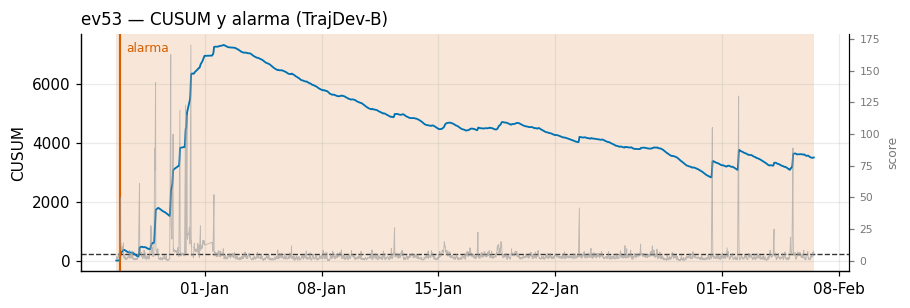

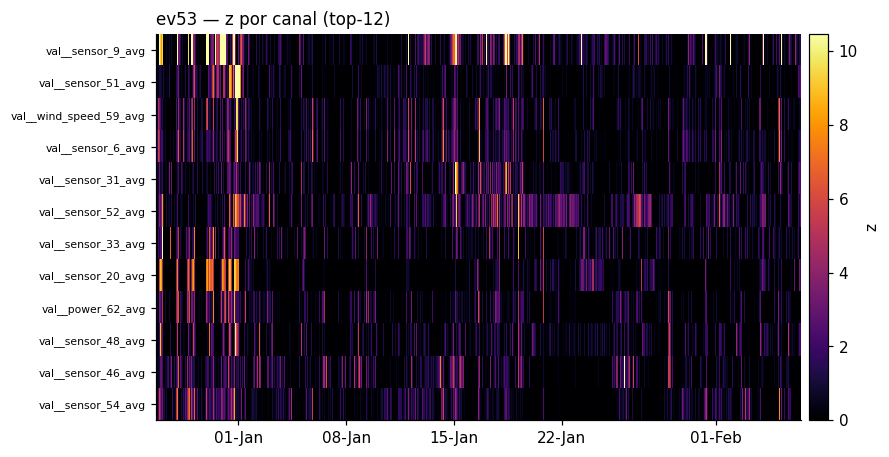

In [9]:
e = 53
m = meta[e]
idx = first_alarm(SW["TrajDev zmax"]["ev_S"][e], H_B)
s_e = trajdev_score(bundle, Z[e]["z"], "dep_zmax_val")
xp.plot_event_timeline(m["window_timestamps"], SW["TrajDev zmax"]["ev_S"][e], H_B, m["labels"],
                       score=s_e, alarm_idx=idx, title="ev53 — CUSUM y alarma (TrajDev-B)")
ax, _ = xp.plot_channel_heatmap(m["window_timestamps"], np.clip(Z[e]["z"], 0, None),
                                bundle["ch_names"], top=12, title=f"ev53 — z por canal (top-12)")
lab = np.asarray(m["labels"], bool)
if idx is not None:
    if lab.any():
        lead = (m["window_timestamps"][np.flatnonzero(lab)[-1]] - m["window_timestamps"][idx]).total_seconds()/3600
        print(f"alarma {m['window_timestamps'][idx]} | antelacion {lead:.0f} h | margen {SW['TrajDev zmax']['ev_S'][e].max()/H_B:.0f}x")
    else:
        print(f"FALSA ALARMA en {m['window_timestamps'][idx]} | margen {SW['TrajDev zmax']['ev_S'][e].max()/H_B:.1f}x")

**Instancia y suficiencia.** Como en C, la anatomía de la ventana del disparo (pronóstico frente a
observado del canal líder) y el contrafactual acumulado, para saber si es un precursor de canal único
o de grupo.

contrafactual acumulado top-k (caida %): k=1:24% k=2:29% k=3:33% k=4:34% k=5:41%
candidatos: ['val__sensor_9_avg', 'val__sensor_20_avg', 'val__sensor_48_avg']


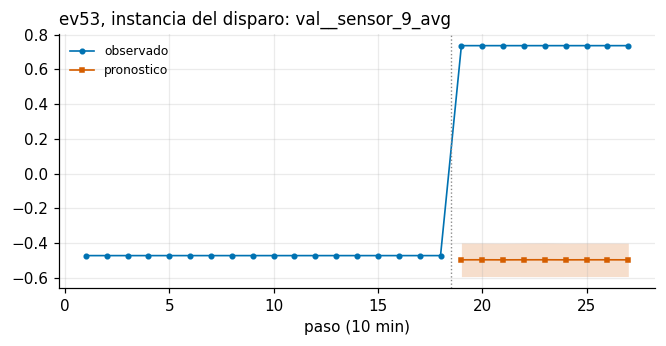

In [10]:
e = 53
idx = first_alarm(SW["TrajDev zmax"]["ev_S"][e], H_B)
win = ev_by_id[e]["data"][idx:idx + 1]
ctx, hh = bundle["arch"]["context"], bundle["arch"]["horizon"]
c_top = int(Z[e]["z"][idx].argmax())
x = torch.tensor(win[:, :ctx, :], dtype=torch.float32, device=DEVICE)
with torch.no_grad():
    preds = np.stack([mm(x).cpu().numpy()[0] for mm in bundle["models"]])
obs, fm, fs = win[0, :, c_top], preds[:, :, c_top].mean(axis=0), preds[:, :, c_top].std(axis=0)
fig, ax = plt.subplots(figsize=(7, 3))
pasos = np.arange(1, ctx + hh + 1)
ax.plot(pasos, obs, marker="o", ms=3, lw=1.1, color=xp.PALETTE[0], label="observado")
ax.plot(pasos[ctx:], fm, marker="s", ms=3, lw=1.1, color=xp.PALETTE[1], label="pronostico")
ax.fill_between(pasos[ctx:], fm - 2 * fs, fm + 2 * fs, color=xp.PALETTE[1], alpha=0.2, lw=0)
ax.axvline(ctx + 0.5, color="#888888", ls=":", lw=0.9)
ax.legend(fontsize=8); ax.set_title(f"ev53, instancia del disparo: {bundle['ch_names'][c_top]}", loc="left")
ax.set_xlabel("paso (10 min)")

def _cfval53():
    wins = ev_by_id[e]["data"][idx:idx + 24]  # noqa: F821 (kernel state)
    cand = list(np.argsort(Z[e]["z"][idx:idx + 24].mean(axis=0))[::-1][:6])
    def sfn(w):
        err, _ = trajdev_forecast_errors(bundle, w)
        return trajdev_score(bundle, trajdev_channel_z(bundle, err)["z"], "dep_zmax_val")
    base = float(sfn(wins).mean())
    cum = np.array([float(sfn(trajdev_counterfactual(bundle, wins, cand[:k])).mean())
                    for k in range(1, 6)])
    return {"cand": np.array(cand), "cum": cum, "base": np.array([base])}

cf = cached("cfval_ev53", _cfval53)
pct = [100 * (1 - c / float(cf["base"][0])) for c in cf["cum"]]
print("contrafactual acumulado top-k (caida %): " + " ".join(f"k={i+1}:{p:.0f}%" for i, p in enumerate(pct)))
print("candidatos:", [bundle["ch_names"][c] for c in cf["cand"][:3]])

**¿Deriva local o relacional?** Es la pregunta simétrica del hallazgo principal del notebook 1. En
C, el precursor más claro era *relacional*, con el contexto dejando de predecir al sensor y el IG
asignando ~90% de la atribución fuera del canal. ¿Y el `sensor_9` de B?

In [11]:
e = 53
idx = first_alarm(SW["TrajDev zmax"]["ev_S"][e], H_B)
lab = np.asarray(meta[e]["labels"], bool)
c_top = int(Z[e]["z"][idx].argmax())
wsel = {"pre-alarma": max(0, idx - 36), "disparo": idx, "pico": int(SW["TrajDev zmax"]["ev_S"][e].argmax())}

def _ig53():
    normal = ev_by_id[e]["data"][~lab][:400]
    # en B el segmento etiquetado cubre todo el evento anomalo
    # baseline = 0
    base = np.median(normal, axis=0) if len(normal) else np.zeros_like(ev_by_id[e]["data"][0])
    att = trajdev_integrated_gradients(bundle, np.stack([ev_by_id[e]["data"][i] for i in wsel.values()]),
                                       c_top, baseline_window=base, steps=50)
    return {"att": att}

ig = cached(f"ig53_v2", _ig53)
ctx = bundle["arch"]["context"]
att = np.abs(ig["att"])
tabla_ig = pd.DataFrame({
    "ventana": list(wsel.keys()),
    "atrib_contexto_%": 100 * att[:, :ctx, :].sum(axis=(1, 2)) / att.sum(axis=(1, 2)),
    "propio_canal_en_ctx_%": 100 * att[:, :ctx, c_top].sum(axis=1) / att[:, :ctx, :].sum(axis=(1, 2)),
})
otros = att[:, :ctx, :].mean(axis=(0, 1)).copy()
otros[c_top] = 0
print(f"canal objetivo: {bundle['ch_names'][c_top]}")
print("canales del CONTEXTO con mas atribucion (excl. el propio):",
      [bundle["ch_names"][i] for i in np.argsort(otros)[::-1][:5]])
tabla_ig.round(1)

canal objetivo: val__sensor_9_avg
canales del CONTEXTO con mas atribucion (excl. el propio): ['val__sensor_40_avg', 'val__sensor_41_avg', 'val__sensor_10_avg', 'val__sensor_6_avg', 'val__sensor_51_avg']


,ventana,atrib_contexto_%,propio_canal_en_ctx_%
0,pre-alarma,76.099998,33.700001
1,disparo,70.300003,28.600000
2,pico,86.500000,13.300000


El patrón de B es **mixto**, y distinto del de C. En el precursor más claro de C, el canal disparador
apenas pesaba en su propia atribución, alrededor del 1%, es decir, deriva relacional pura. Aquí, el
propio `sensor_9` concentra el **29-34%** de la atribución del contexto en la pre-alarma y el
disparo, de modo que un tercio de la señal es el sensor desviándose y arrastrando su pronóstico,
mientras los dos tercios restantes se reparten entre vecinos (`sensor_40/41/10/6`). Hacia el pico, el
peso propio cae al 13% y el precursor se vuelve más relacional.

Es la tercera cara del mismo diagnóstico del parque, porque en B nada es puro, ni los precursores de
canal único (en el apartado 4.1 el contrafactual acumulado solo recorta un 41%), ni la deriva local,
ni la relacional. La atribución de instancia permite decirlo con números en lugar de intuirlo.

### 4.2 ev77, la anomalía que dispara por otro sensor

alarma 2023-05-30 11:30:00 | antelacion 1476 h | margen 25x


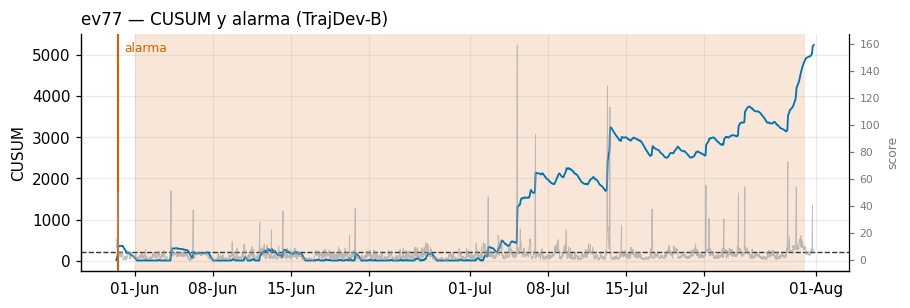

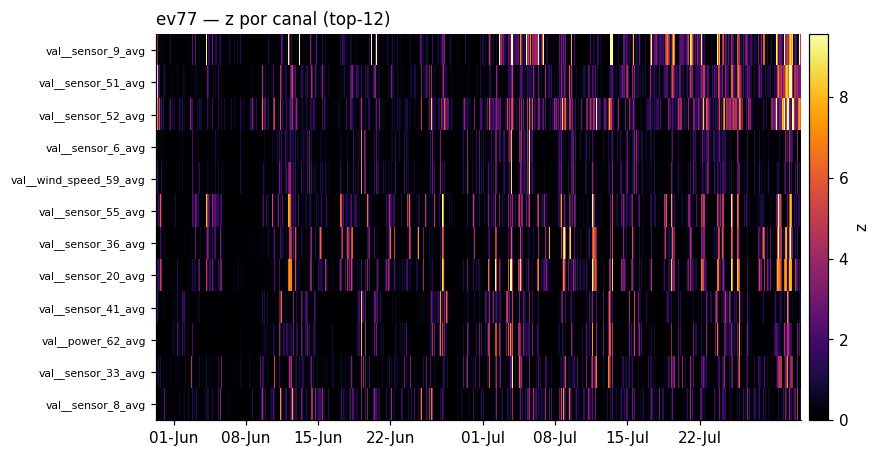

In [12]:
e = 77
m = meta[e]
idx = first_alarm(SW["TrajDev zmax"]["ev_S"][e], H_B)
s_e = trajdev_score(bundle, Z[e]["z"], "dep_zmax_val")
xp.plot_event_timeline(m["window_timestamps"], SW["TrajDev zmax"]["ev_S"][e], H_B, m["labels"],
                       score=s_e, alarm_idx=idx, title="ev77 — CUSUM y alarma (TrajDev-B)")
ax, _ = xp.plot_channel_heatmap(m["window_timestamps"], np.clip(Z[e]["z"], 0, None),
                                bundle["ch_names"], top=12, title=f"ev77 — z por canal (top-12)")
lab = np.asarray(m["labels"], bool)
if idx is not None:
    if lab.any():
        lead = (m["window_timestamps"][np.flatnonzero(lab)[-1]] - m["window_timestamps"][idx]).total_seconds()/3600
        print(f"alarma {m['window_timestamps'][idx]} | antelacion {lead:.0f} h | margen {SW['TrajDev zmax']['ev_S'][e].max()/H_B:.0f}x")
    else:
        print(f"FALSA ALARMA en {m['window_timestamps'][idx]} | margen {SW['TrajDev zmax']['ev_S'][e].max()/H_B:.1f}x")

### 4.3 ev86, anatomía de una falsa alarma

El caso que en C no hizo falta y en B es obligatorio. El mismo instrumental, timeline, heatmap e
instancia del disparo, aplicado a un periodo **normal** donde el CUSUM cruza el umbral. La pregunta
es si la falsa alarma tiene estructura, es decir, un sensor concreto comportándose de forma
anómala de verdad, quizá por un mal etiquetado o un mantenimiento no registrado, o si es ruido difuso
amplificado.

FALSA ALARMA en 2023-05-14 16:00:00 | margen 2.6x


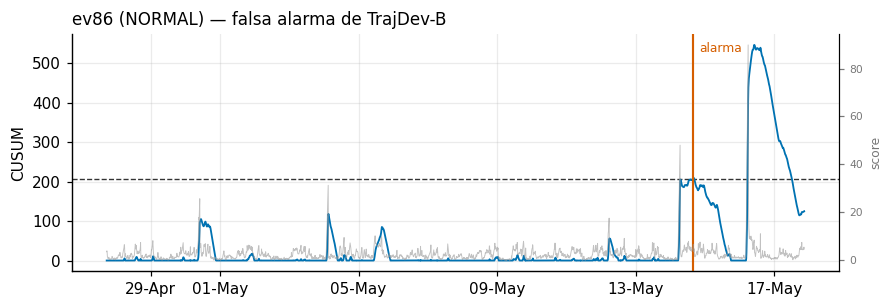

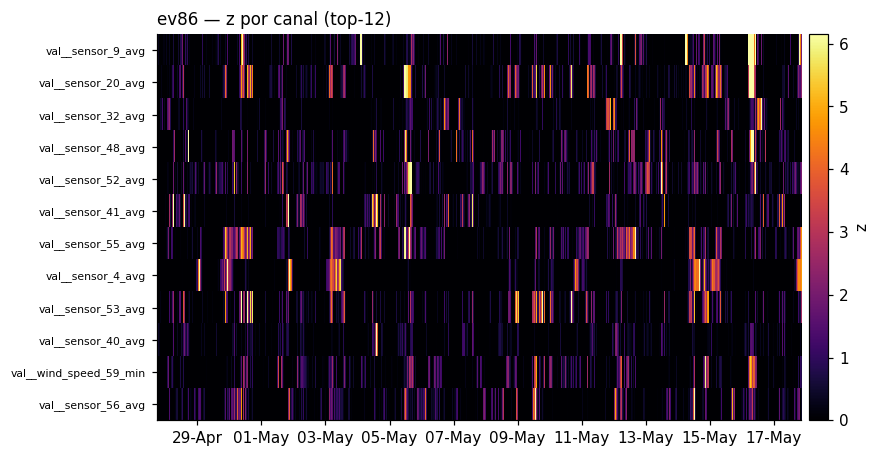

In [13]:
e = 86
m = meta[e]
idx = first_alarm(SW["TrajDev zmax"]["ev_S"][e], H_B)
s_e = trajdev_score(bundle, Z[e]["z"], "dep_zmax_val")
xp.plot_event_timeline(m["window_timestamps"], SW["TrajDev zmax"]["ev_S"][e], H_B, m["labels"],
                       score=s_e, alarm_idx=idx, title="ev86 (NORMAL) — falsa alarma de TrajDev-B")
ax, _ = xp.plot_channel_heatmap(m["window_timestamps"], np.clip(Z[e]["z"], 0, None),
                                bundle["ch_names"], top=12, title=f"ev86 — z por canal (top-12)")
lab = np.asarray(m["labels"], bool)
if idx is not None:
    if lab.any():
        lead = (m["window_timestamps"][np.flatnonzero(lab)[-1]] - m["window_timestamps"][idx]).total_seconds()/3600
        print(f"alarma {m['window_timestamps'][idx]} | antelacion {lead:.0f} h | margen {SW['TrajDev zmax']['ev_S'][e].max()/H_B:.0f}x")
    else:
        print(f"FALSA ALARMA en {m['window_timestamps'][idx]} | margen {SW['TrajDev zmax']['ev_S'][e].max()/H_B:.1f}x")

canal de la falsa alarma: val__sensor_4_avg | z = 6.6


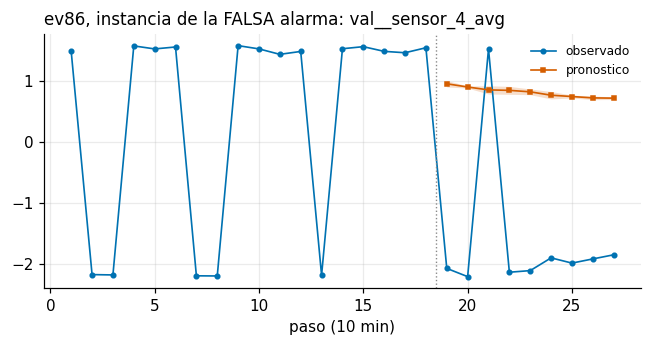

In [14]:
e = 86
idx = first_alarm(SW["TrajDev zmax"]["ev_S"][e], H_B)
z86 = Z[e]["z"]
c86 = int(z86[idx].argmax()) if idx is not None else int(z86.max(axis=0).argmax())
# la instancia de la falsa alarma
win = ev_by_id[e]["data"][idx:idx + 1]
ctx, hh = bundle["arch"]["context"], bundle["arch"]["horizon"]
x = torch.tensor(win[:, :ctx, :], dtype=torch.float32, device=DEVICE)
with torch.no_grad():
    preds = np.stack([mm(x).cpu().numpy()[0] for mm in bundle["models"]])
obs, fm, fs = win[0, :, c86], preds[:, :, c86].mean(axis=0), preds[:, :, c86].std(axis=0)
fig, ax = plt.subplots(figsize=(7, 3))
pasos = np.arange(1, ctx + hh + 1)
ax.plot(pasos, obs, marker="o", ms=3, lw=1.1, color=xp.PALETTE[0], label="observado")
ax.plot(pasos[ctx:], fm, marker="s", ms=3, lw=1.1, color=xp.PALETTE[1], label="pronostico")
ax.fill_between(pasos[ctx:], fm - 2 * fs, fm + 2 * fs, color=xp.PALETTE[1], alpha=0.2, lw=0)
ax.axvline(ctx + 0.5, color="#888888", ls=":", lw=0.9)
ax.legend(fontsize=8)
ax.set_title(f"ev86, instancia de la FALSA alarma: {bundle['ch_names'][c86]}", loc="left")
ax.set_xlabel("paso (10 min)")
print(f"canal de la falsa alarma: {bundle['ch_names'][c86]} | z = {z86[idx, c86]:.1f}" if idx is not None
      else "sin cruce")

No es el `sensor_9` que disparaba 5 de las 6 anomalías, dispara `sensor_4` (z ≈ 6.6, margen 2.6×).
La instancia muestra que no es ruido difuso amplificado, porque la señal se aparta de verdad de su
pronóstico, pero la desviación es transitoria y no tiene consecuencias. Esa es la naturaleza del
ruido de B, no un fondo uniforme sino **episodios locales con estructura** (¿regímenes de operación
atípicos?, ¿mantenimientos no etiquetados?) que un detector no puede distinguir de un precursor
incipiente sin más contexto que el SCADA.

Encaja con el otro hallazgo del notebook, que hasta la detección más nítida (ev53) reparte su
precursor entre muchos canales, porque el contrafactual acumulado solo recorta un 24% con el canal
líder y un 41% con los cinco primeros, frente al 64-93% de los casos de C. En B todo es más difuso,
tanto los fallos como las falsas alarmas.

## 5. TrajDev y el autoencoder ante el mismo parque

En C encontramos un caso, ev4, donde ambos modelos miraban físicas distintas. En B, con 30 sensores y
un modo de fallo dominante, la pregunta es si las atribuciones convergen. Comparamos el ranking de
sensores de ambos en ev53, el z de TrajDev frente al residuo por sensor del AE-B, con la misma cadena
reproducible que en los notebooks anteriores.


TrajDev top-8: ['sensor_9', 'sensor_52', 'sensor_5', 'sensor_46', 'sensor_41', 'sensor_54', 'sensor_6', 'wind_speed_59_min']
AE      top-8: ['sensor_47', 'sensor_33', 'sensor_36', 'sensor_53', 'sensor_5', 'wind_speed_59', 'sensor_10', 'sensor_6']
solape: ['sensor_5', 'sensor_6']


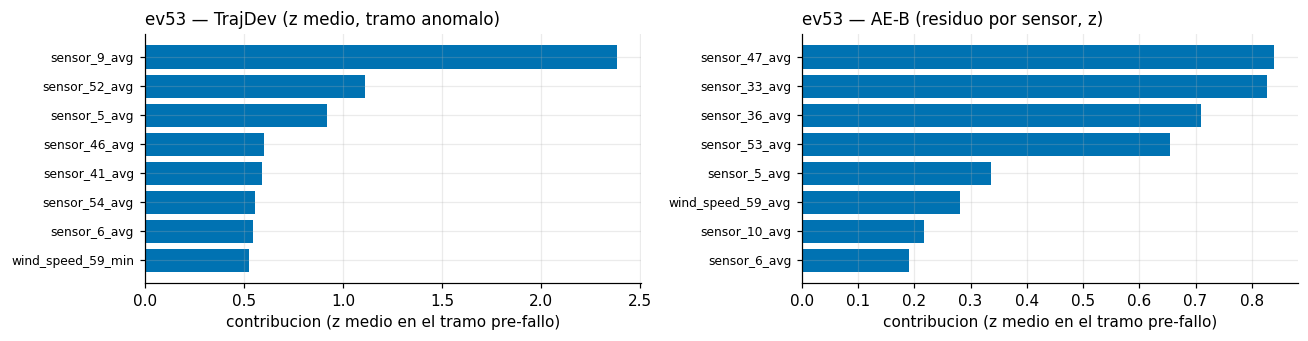

In [15]:
ae_b = load_ae(FARM)
aevs = {x["event_id"]: x for x in load_ae_events(FARM)}

def _ae53():
    a = aevs[53]
    res = ae_residual_sensor(ae_b, a["raw"])
    lab = np.asarray(meta[53]["labels"], bool)
    normal = res[~lab] if (~lab).any() else res[:200]
    mu_r, sd_r = residual_train_stats(normal)
    return {"zres": (res - mu_r) / sd_r}

zres = cached("ae_res_ev53", _ae53)["zres"]
lab = np.asarray(meta[53]["labels"], bool)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
xp.plot_sensor_ranking(Z[53]["z"][lab].mean(axis=0),
                       [c.replace("val__", "") for c in bundle["ch_names"]], top=8, ax=axes[0],
                       title="ev53 — TrajDev (z medio, tramo anomalo)")
xp.plot_sensor_ranking(zres[lab].mean(axis=0), ae_b["feats"], top=8, ax=axes[1],
                       title="ev53 — AE-B (residuo por sensor, z)")
plt.tight_layout()
td8 = [bundle["ch_names"][i].replace("val__", "").replace("_avg", "") for i in np.argsort(Z[53]["z"][lab].mean(axis=0))[::-1][:8]]
ae8 = [f.replace("_avg", "") for f in np.array(ae_b["feats"])[np.argsort(zres[lab].mean(axis=0))[::-1][:8]]]
print("TrajDev top-8:", td8)
print("AE      top-8:", ae8)
print("solape:", sorted(set(td8) & set(ae8)))

## 6. Conclusiones y limitaciones

1. **La receta viaja.** Sin un solo ajuste, TrajDev supera en B al autoencoder de referencia en 4 de las 5
   semillas, igual que en C, porque pierde solo la semilla afortunada, y con la mejor estabilidad
   multi-semilla del parque, ±0.008 frente a ±0.029 del AE. En un parque donde la línea base oscila
   el triple, la estabilidad *es* el resultado.
2. **La explicabilidad nativa también viaja, y simplifica.** Cinco de seis anomalías se rastrean a
   un único sensor (`sensor_9`) y la sexta a `sensor_51`, con instancias y contrafactuales que se
   leen igual que en C.
3. **El techo de B queda caracterizado y explicado.** Las anomalías son fáciles, con 300 a 1 476 h
   de antelación para todos, y lo difícil es callar, porque todos los detectores dan falsas alarmas
   en la mayoría de los 9 periodos normales. La anatomía de una de ellas, en el apartado 4.3,
   muestra a qué se parece el ruido que las provoca. El CARE de ~0.70 de B no es un fallo de ningún
   modelo, es el parque.

**Limitaciones.**

1. Con 6 anomalías y un modo de fallo dominante, B tiene poca potencia para discriminar modelos, de
   ahí el énfasis multi-semilla.
2. El AE comparado a nivel de pesos es la cadena reproducible (0.7213), no los pesos originales del
   despliegue.
3. Las estadísticas de normalidad por evento siguen la misma convención conservadora que los
   notebooks anteriores.

## Referencias

- Gück, C., Roelofs, C. M. A., Faulstich, S. (2024). *CARE to Compare: A Real-World Benchmark
  Dataset for Early Fault Detection in Wind Turbine Data.* Data, 9(12), 138.
- Roelofs, C. M. A., Lutz, M.-A., Faulstich, S., Vogt, S. (2021). *Autoencoder-based anomaly root
  cause analysis for wind turbines* (ARCANA). Energy and AI, 4, 100065.
- Idé, T., Dhurandhar, A., Navrátil, J., Singh, M., Abe, N. (2021). *Anomaly Attribution with
  Likelihood Compensation.* Proceedings of the 35th AAAI Conference on Artificial Intelligence,
  35, 4131-4138.
- Westerhuis, J. A., Gurden, S. P., Smilde, A. K. (2000). *Contribution plots for statistical
  process control: analysis of the smearing-out effect.*
- Li, Z., Zhu, Y., van Leeuwen, M. (2023). *A Survey on Explainable Anomaly Detection.* ACM
  Transactions on Knowledge Discovery from Data, 18(1), 23:1-23:54.
- Cummins, L., Sommers, A., Bakhtiari Ramezani, S., Mittal, S., Jabour, J., Seale, M., Rahimi, S.
  (2024). *Explainable Predictive Maintenance: A Survey of Current Methods, Challenges and
  Opportunities.* IEEE Access, 12, 57574-57602.
- Sundararajan, M., Taly, A., Yan, Q. (2017). *Axiomatic Attribution for Deep Networks* (Integrated
  Gradients). Proceedings of the 34th International Conference on Machine Learning (ICML), PMLR 70,
  3319-3328. Implementación, Captum (PyTorch).
- Su, Y., Zhao, Y., Niu, C., Liu, R., Sun, W., Pei, D. (2019). *Robust Anomaly Detection for
  Multivariate Time Series through Stochastic Recurrent Neural Network* (OmniAnomaly). KDD 2019.